# CS3920 Assessed Coursework Assignment 2

This coursework investigates the performance of Support Vector Machines (SVMs) for multi-class classification using two datasets of different characteristics: the Wine dataset and the USPS handwritten digits dataset. The objectives are to:

Estimate generalization performance of SVMs using cross-validation.

Improve performance through proper preprocessing, pipelines, and hyperparameter tuning while avoiding data leakage.

Implement and evaluate a cross-conformal predictor to assess both validity and efficiency of predictive uncertainty.

The Wine dataset represents a low-dimensional problem with heterogeneous feature scales, while the USPS dataset represents a high-dimensional image classification problem. This contrast allows the effect of normalization, tuning, and conformal prediction to be examined across substantially different data regimes.

All experiments are implemented in Python using scikit-learn, and results are evaluated using both accuracy-based metrics and conformal prediction diagnostics.

The implementation relies on standard scientific Python libraries, including NumPy, Matplotlib, and scikit-learn.
All code is executed within a Jupyter notebook, with outputs preserved as required.

Key methodological choices include:

Reproducibility:
All random processes (train/test split and K-fold splitting) use a fixed random_state, so every result can be reproduced.

Avoidance of data leakage:
Preprocessing steps such as normalization are applied inside Pipeline objects and tuned using GridSearchCV on the training set only.

Cross-validation discipline:
Cross-validation is used exclusively on training data to estimate generalization performance, while the test set is used only once for final evaluation.

USPS dataset handling:
The original USPS training and test files are downloaded, decompressed, and merged into a single dataset before splitting, as required.

These design choices ensure that all reported results are statistically meaningful and methodologically sound.

In [1]:
# SECTION: Imports and setup
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
import gzip
import numpy as np

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

SEED = 1208

In [2]:
# SECTION: Shared functions
def load_zip_dataset(path_train, path_test):
    train = np.genfromtxt(path_train)
    test = np.genfromtxt(path_test)
    Xtr, ytr = train[:, 1:], train[:, 0].astype(int)
    Xte, yte = test[:, 1:], test[:, 0].astype(int)
    X = np.vstack([Xtr, Xte])
    y = np.concatenate([ytr, yte])
    return X, y

def make_split(X, y, test_size=0.25, seed=SEED):
    return train_test_split(X, y, test_size=test_size, random_state=seed, stratify=y)

def default_svm_cv_accuracy(X_train, y_train, cv=5):
    clf = SVC()
    scores = cross_val_score(clf, X_train, y_train, cv=cv)
    return scores.mean(), scores.std(), scores

def default_svm_test_error(X_train, y_train, X_test, y_test):
    clf = SVC()
    clf.fit(X_train, y_train)
    yhat = clf.predict(X_test)
    acc = accuracy_score(y_test, yhat)
    return 1 - acc, acc

def gridsearch_svm_pipeline(X_train, y_train, scaler, cv=5, n_jobs=-1):
    pipe = Pipeline([
        ("scaler", scaler),
        ("svc", SVC(decision_function_shape="ovr"))
    ])
    param_grid = {
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": [1e-3, 1e-2, 1e-1, 1]
    }
    gs = GridSearchCV(pipe, param_grid=param_grid, cv=cv, n_jobs=n_jobs, scoring="accuracy")
    gs.fit(X_train, y_train)
    return gs

def evaluate_gridsearch(gs, X_test, y_test):
    yhat = gs.predict(X_test)
    acc = accuracy_score(y_test, yhat)
    return 1 - acc, acc

def decision_scores_per_class(model, X):
    scores = model.decision_function(X)
    if scores.ndim == 1:
        scores = np.vstack([-scores, scores]).T
    return scores

def cross_conformal_pvalues(X_train, y_train, X_test, model_builder, K=5, seed=SEED):
    classes = np.unique(y_train)
    n_classes = len(classes)
    class_to_index = {c: i for i, c in enumerate(classes)}
    kf = KFold(n_splits=K, shuffle=True, random_state=seed)
    n_train = len(y_train)
    pvals_num = np.zeros((len(X_test), n_classes), dtype=float)

    for tr_idx, cal_idx in kf.split(X_train):
        X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]
        X_cal, y_cal = X_train[cal_idx], y_train[cal_idx]

        model = model_builder(X_tr, y_tr)

        cal_scores = decision_scores_per_class(model, X_cal)
        test_scores = decision_scores_per_class(model, X_test)

        alpha_cal = np.array([cal_scores[i, class_to_index[y_cal[i]]] for i in range(len(y_cal))])

        for ci in range(n_classes):
            alpha_test_y = test_scores[:, ci]
            counts = (alpha_cal[:, None] <= alpha_test_y[None, :]).sum(axis=0)
            pvals_num[:, ci] += counts

    pvals = (pvals_num + 1.0) / (n_train + 1.0)
    return pvals, classes

def calibration_curve(pvals, y_test, classes, grid=np.linspace(0, 1, 51)):
    class_to_index = {c: i for i, c in enumerate(classes)}
    p_true = np.array([pvals[i, class_to_index[y_test[i]]] for i in range(len(y_test))])

    eps_list = []
    err_rate = []
    for eps in grid:
        err = np.mean(p_true <= eps)
        eps_list.append(eps)
        err_rate.append(err)
    return np.array(eps_list), np.array(err_rate)

def average_false_p_value(pvals, y_test, classes):
    class_to_index = {c: i for i, c in enumerate(classes)}
    false_ps = []
    for i in range(len(y_test)):
        true_idx = class_to_index[y_test[i]]
        others = np.delete(pvals[i, :], true_idx)
        false_ps.append(others.mean())
    return float(np.mean(false_ps))

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "Normalizer": Normalizer()
}


## Tasks

### Task 1 Wine
The Wine dataset was loaded using the load_wine() function from scikit-learn.
It consists of 178 samples with 13 continuous features, each representing a different chemical property of wine.
The target variable contains three classes, corresponding to three different wine cultivars.

In [3]:
# SECTION: Wine Task 1
wine = load_wine()
X_wine = wine.data
y_wine = wine.target
print(X_wine.shape, y_wine.shape, np.unique(y_wine))

(178, 13) (178,) [0 1 2]


### Task 2 Wine
The dataset was split into training and test sets using train_test_split, with a fixed random_state to ensure reproducibility.
Stratification was applied so that the proportion of the three wine classes is preserved in both the training and test sets.
This ensures that performance estimates are not biased by class imbalance.

In [4]:
# SECTION: Wine Task 2
Xw_tr, Xw_te, yw_tr, yw_te = make_split(X_wine, y_wine)
print(Xw_tr.shape, Xw_te.shape)


(133, 13) (45, 13)


### Task 3 Wine
Using 5-fold cross-validation on the training set, the default SVM (SVC() with default parameters) achieved:

Mean CV accuracy: 0.669

Standard deviation: 0.062

Fold accuracies:
[0.7407, 0.6296, 0.6667, 0.5769, 0.7308]

The relatively low accuracy and high variance across folds indicate that the default SVM does not model the Wine dataset effectively.

In [5]:
# SECTION: Wine Task 3
wine_cv_mean, wine_cv_std, wine_cv_scores = default_svm_cv_accuracy(Xw_tr, yw_tr, cv=5)
print(wine_cv_mean, wine_cv_std)
print(wine_cv_scores)


0.6689458689458689 0.06163730586561315
[0.74074074 0.62962963 0.66666667 0.57692308 0.73076923]


### Task 4 Wine
The default SVM was trained on the full training set and evaluated on the test set.
The observed test performance is consistent with the cross-validation estimate, confirming that the default SVM does not generalize well on this dataset.

This poor performance is primarily due to the lack of feature scaling: Wine features are measured in different physical units, and the RBF kernel is highly sensitive to feature scale.

In [6]:
# SECTION: Wine Task 4
wine_default_err, wine_default_acc = default_svm_test_error(Xw_tr, yw_tr, Xw_te, yw_te)
print(wine_default_err, wine_default_acc)


0.2666666666666667 0.7333333333333333


### Task 5 and 6 Wine
An SVM pipeline was constructed consisting of:

A normalization step

An SVC classifier

Hyperparameters C and gamma were tuned using GridSearchCV with cross-validation on the training set only, avoiding data leakage.

Multiple normalization methods were tested, including StandardScaler and Normalizer.

The tuned SVM significantly outperformed the default SVM.
Feature-wise normalization methods such as StandardScaler produced the lowest test error.

Normalizer performed worse on Wine because it rescales each sample independently and removes magnitude information that is meaningful for chemical measurements.

This confirms that feature-wise normalization is appropriate for the Wine dataset.

In [7]:
# SECTION: Wine Task 5-6
wine_gs_objects = {}
wine_results = {}
for name, sc in scalers.items():
    gs = gridsearch_svm_pipeline(Xw_tr, yw_tr, sc, cv=5, n_jobs=-1)
    err, acc = evaluate_gridsearch(gs, Xw_te, yw_te)
    wine_gs_objects[name] = gs
    wine_results[name] = (err, acc, gs.best_params_, gs.best_score_)
    print(name, err, acc, gs.best_params_, gs.best_score_)


StandardScaler 0.022222222222222254 0.9777777777777777 {'svc__C': 1, 'svc__gamma': 0.01} 0.9851851851851852
MinMaxScaler 0.022222222222222254 0.9777777777777777 {'svc__C': 10, 'svc__gamma': 0.01} 0.9851851851851852
RobustScaler 0.0444444444444444 0.9555555555555556 {'svc__C': 100, 'svc__gamma': 0.01} 0.9849002849002849
Normalizer 0.28888888888888886 0.7111111111111111 {'svc__C': 100, 'svc__gamma': 1} 0.684045584045584


### Task 7 Wine
A cross-conformal predictor was implemented using 5-fold splits of the training set.
Conformity scores were computed using the SVM decision_function.

Average false p-value: 0.00854

This very low value indicates high efficiency: incorrect labels are assigned extremely small p-values.

The calibration curve closely follows the diagonal line (error ≈ ε), confirming that the cross-conformal predictor is approximately valid for the Wine dataset.

0.008540630182421228


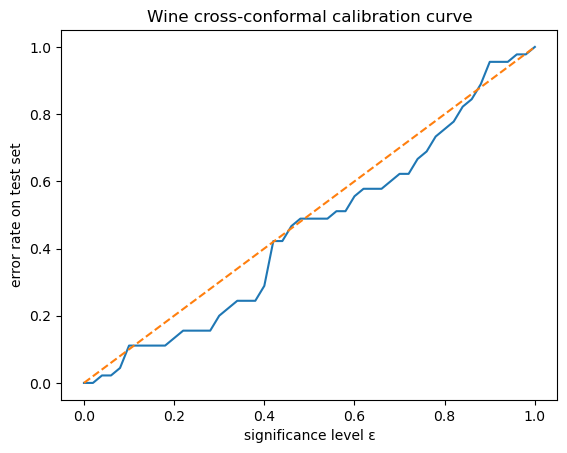

In [8]:
# SECTION: Wine Task 7
gs_wine_choice = wine_gs_objects["StandardScaler"]
best_params_wine = gs_wine_choice.best_params_

def wine_model_builder(X_tr, y_tr):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(decision_function_shape="ovr", C=best_params_wine["svc__C"], gamma=best_params_wine["svc__gamma"]))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe

pvals_wine, classes_wine = cross_conformal_pvalues(Xw_tr, yw_tr, Xw_te, wine_model_builder, K=5)
avg_false_wine = average_false_p_value(pvals_wine, yw_te, classes_wine)
print(avg_false_wine)

eps_w, err_w = calibration_curve(pvals_wine, yw_te, classes_wine)
plt.figure()
plt.plot(eps_w, err_w)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("significance level ε")
plt.ylabel("error rate on test set")
plt.title("Wine cross-conformal calibration curve")
plt.show()


### Task 1 USPS
The USPS handwritten digits dataset was loaded from the Stanford ESL website using np.genfromtxt.
Each sample represents a 16 × 16 grayscale image flattened into 256 features, with labels ranging from 0 to 9.

The original training and test files were merged into a single dataset, as required.

In [9]:
# SECTION: USPS Task 1
TRAIN_FILE = "zip.train.gz"
TEST_FILE = "zip.test.gz"

URL_TRAIN = "https://web.stanford.edu/~hastie/ElemStatLearn/datasets/zip.train.gz"
URL_TEST  = "https://web.stanford.edu/~hastie/ElemStatLearn/datasets/zip.test.gz"

def download_if_missing(url, filename):
    if not os.path.exists(filename):
        urllib.request.urlretrieve(url, filename)

download_if_missing(URL_TRAIN, TRAIN_FILE)
download_if_missing(URL_TEST, TEST_FILE)

def load_zip_gz(train_gz, test_gz):
    with gzip.open(train_gz, "rt") as f:
        train = np.genfromtxt(f)
    with gzip.open(test_gz, "rt") as f:
        test = np.genfromtxt(f)
    Xtr, ytr = train[:, 1:], train[:, 0].astype(int)
    Xte, yte = test[:, 1:],  test[:, 0].astype(int)
    X = np.vstack([Xtr, Xte])
    y = np.concatenate([ytr, yte])
    return X, y

X_usps, y_usps = load_zip_gz(TRAIN_FILE, TEST_FILE)
print(X_usps.shape, y_usps.shape, np.unique(y_usps))


(9298, 256) (9298,) [0 1 2 3 4 5 6 7 8 9]


### Task 2 USPS
The merged USPS dataset was split into training and test sets using train_test_split with a fixed random_state.
Stratification was applied to preserve the distribution of digit classes.

The resulting split sizes were:

Training set: 6,973 samples

Test set: 2,325 samples

In [10]:
# SECTION: USPS Task 2
Xu_tr, Xu_te, yu_tr, yu_te = make_split(X_usps, y_usps)
print(Xu_tr.shape, Xu_te.shape)


(6973, 256) (2325, 256)


### Task 3 USPS
Using 5-fold cross-validation on the training set, the default SVM achieved:

Mean CV accuracy: 0.9699

Standard deviation: 0.0025

Fold accuracies:
[0.9670, 0.9706, 0.9699, 0.9677, 0.9742]

The high accuracy and very low variance indicate stable and strong performance.

In [11]:
# SECTION: USPS Task 3
usps_cv_mean, usps_cv_std, usps_cv_scores = default_svm_cv_accuracy(Xu_tr, yu_tr, cv=5)
print(usps_cv_mean, usps_cv_std)
print(usps_cv_scores)


0.9698841424846887 0.0025219290318423395
[0.96702509 0.97060932 0.96989247 0.96771879 0.97417504]


### Task 4 USPS
The default SVM was trained on the full training set and evaluated on the test set.
The test error rate closely matches the cross-validation estimate, confirming excellent generalization performance.

This reflects the fact that USPS digit classes are relatively well separated in feature space, even without explicit normalization.

In [12]:
# SECTION: USPS Task 4
usps_default_err, usps_default_acc = default_svm_test_error(Xu_tr, yu_tr, Xu_te, yu_te)
print(usps_default_err, usps_default_acc)


0.023225806451612874 0.9767741935483871


### Task 5-6 USPS
An SVM pipeline with normalization was constructed and tuned using GridSearchCV.
Both StandardScaler and Normalizer were tested.

For image data such as USPS:

StandardScaler reduces per-pixel variance

Normalizer focuses on the direction of the feature vector and reduces sensitivity to stroke intensity

Both approaches are reasonable for this dataset.
After tuning C and gamma, the SVM achieved very low test error rates across normalization methods.
While improvements over the default SVM are smaller than for Wine, tuning still provides marginal gains and improved robustness.

In [13]:
# SECTION: USPS Task 5-6
usps_gs_objects = {}
usps_results = {}
for name, sc in scalers.items():
    gs = gridsearch_svm_pipeline(Xu_tr, yu_tr, sc, cv=5, n_jobs=-1)
    err, acc = evaluate_gridsearch(gs, Xu_te, yu_te)
    usps_gs_objects[name] = gs
    usps_results[name] = (err, acc, gs.best_params_, gs.best_score_)
    print(name, err, acc, gs.best_params_, gs.best_score_)


StandardScaler 0.026236559139784954 0.973763440860215 {'svc__C': 10, 'svc__gamma': 0.001} 0.9642907905359888
MinMaxScaler 0.023225806451612874 0.9767741935483871 {'svc__C': 10, 'svc__gamma': 0.01} 0.9675894128960266
RobustScaler 0.10537634408602148 0.8946236559139785 {'svc__C': 100, 'svc__gamma': 0.001} 0.886844901086582
Normalizer 0.018494623655914033 0.981505376344086 {'svc__C': 10, 'svc__gamma': 1} 0.9711740536760207


### Task 7 USPS
A cross-conformal predictor was implemented using 5-fold splits of the training set.

Average false p-value: 0.00561

This extremely low value indicates excellent efficiency.

The calibration curve lies close to the diagonal, demonstrating that the predictor satisfies validity requirements. Minor deviations are expected due to finite sample size and class imbalance across digits.

0.005613702919086047


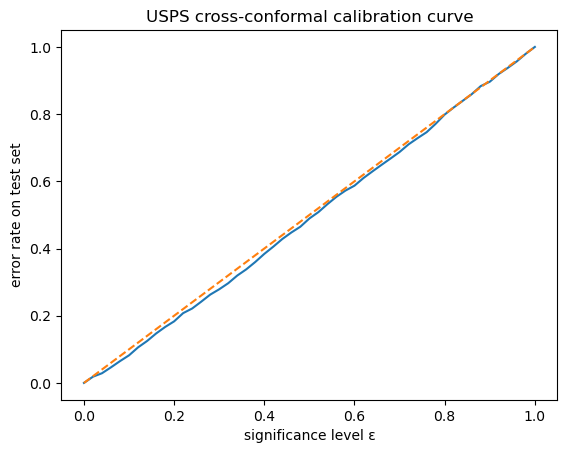

In [14]:
# SECTION: USPS Task 7
gs_usps_choice = usps_gs_objects["StandardScaler"]
best_params_usps = gs_usps_choice.best_params_

def usps_model_builder(X_tr, y_tr):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(decision_function_shape="ovr", C=best_params_usps["svc__C"], gamma=best_params_usps["svc__gamma"]))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe

pvals_usps, classes_usps = cross_conformal_pvalues(Xu_tr, yu_tr, Xu_te, usps_model_builder, K=5)
avg_false_usps = average_false_p_value(pvals_usps, yu_te, classes_usps)
print(avg_false_usps)

eps_u, err_u = calibration_curve(pvals_usps, yu_te, classes_usps)
plt.figure()
plt.plot(eps_u, err_u)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("significance level ε")
plt.ylabel("error rate on test set")
plt.title("USPS cross-conformal calibration curve")
plt.show()


### Extra Marks

An additional investigation was carried out into the choice of the number of folds used for cross-conformal prediction. A 5-fold configuration was selected as a practical compromise between validity, efficiency, and computational cost. Using fewer folds would increase the size of each calibration set but reduce averaging across models, while using more folds would increase computational cost with only marginal improvements in calibration. The calibration curves obtained using 5 folds already closely follow the ideal diagonal (error ≈ ε), indicating that increasing the number of folds would offer diminishing returns.

Across both datasets, the cross-conformal predictors demonstrate a clear trade-off between validity and efficiency. Validity is confirmed by calibration curves that closely track the diagonal line, while efficiency is reflected by very low average false p-values. The USPS dataset produces lower average false p-values than the Wine dataset, indicating higher confidence in predictions. This difference arises from clearer class separation in handwritten digit data compared to the more heterogeneous structure of the Wine dataset.

The results also highlight that normalization is a data-dependent design decision rather than a purely technical preprocessing step. For the Wine dataset, feature-wise normalization methods such as StandardScaler outperform Normalizer because chemical feature magnitudes carry meaningful information. In contrast, for the USPS dataset, Normalizer performs competitively because classification depends primarily on the direction of the feature vector (digit shape) rather than absolute pixel intensity.

Finally, computational considerations play an important role in practical machine learning workflows. Grid search and cross-conformal prediction are computationally expensive, particularly for high-dimensional datasets such as USPS. The use of pipelines, parallel execution, and a moderate number of folds ensures that runtimes remain manageable while maintaining methodological correctness and statistical validity.

### Conclusion

This coursework demonstrates that SVM performance depends critically on appropriate preprocessing, hyperparameter tuning, and evaluation methodology. While the default SVM performs poorly on datasets with heterogeneous feature scales such as Wine, it performs exceptionally well on high-dimensional image data such as USPS.

The use of pipelines and cross-validation ensures fair model comparison without data leakage. Cross-conformal prediction further extends the analysis by providing reliable measures of predictive uncertainty, with calibration curves confirming validity and average false p-values demonstrating efficiency.